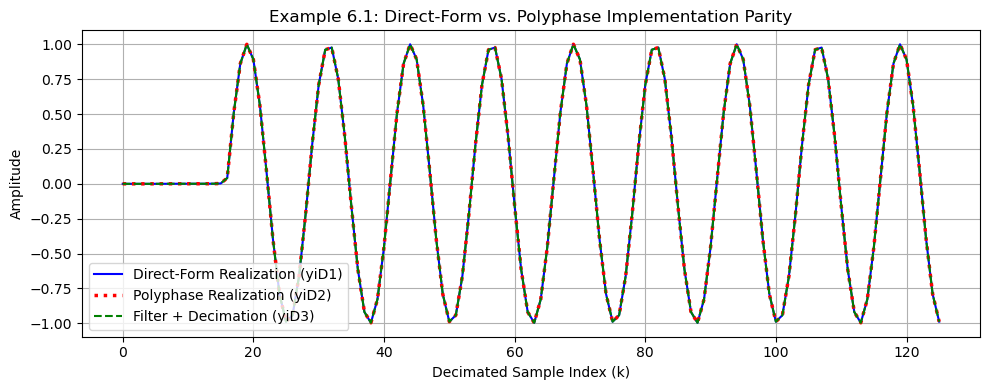

Max difference (Direct vs Polyphase)           : 3.33e-16
Max difference (Direct vs Filter+Decimation)   : 2.22e-16


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, lfilter

# ==========================================
# 1. Setup Parameters & Input Signal
# ==========================================
n_samples = 1001
ui = np.sin(2 * np.pi * 0.01 * np.arange(n_samples)) # Sine wave input signal
N = 8                                                # Number of subbands
M = 256                                              # Length of filter
w = firwin(M, cutoff=1.0 / 4.0, fs=2.0)              # Target weight vector

# ==========================================
# 2. Direct-Form Realization
# ==========================================
x_direct = np.zeros(M)
yiD1 = []
for n in range(n_samples):
    x_direct = np.concatenate(([ui[n]], x_direct[:-1])) # Update tapped-delay line
    if n % N == 0:
        yiD1.append(np.dot(w, x_direct))               # Direct-form output at decimation rate
yiD1 = np.array(yiD1)

# ==========================================
# 3. Polyphase Realization
# ==========================================
# Polyphase decomposition (reshaping into N rows x (M/N) columns using Fortran order)
W_poly = w.reshape(N, M // N, order='F')
X_poly = np.zeros((N, M // N))
xN_buf = np.zeros(N)

yiD2 = []
for n in range(n_samples):
    xN_buf = np.concatenate(([ui[n]], xN_buf[:-1]))
    if n % N == 0:
        X_poly = np.hstack((xN_buf.reshape(-1, 1), X_poly[:, :-1])) # Update polyphase buffer
        yiD2.append(np.sum(W_poly * X_poly))                         # Polyphase sum output
yiD2 = np.array(yiD2)

# ==========================================
# 4. Standard Filtering followed by Decimation
# ==========================================
yi3 = lfilter(w, [1.0], ui)
yiD3 = yi3[::N]

# ==========================================
# 5. Parity Verification & Plotting
# ==========================================
plt.figure(figsize=(10, 4))
plt.plot(yiD1, 'b', label='Direct-Form Realization (yiD1)')
plt.plot(yiD2, 'r:', label='Polyphase Realization (yiD2)', linewidth=2.5)
plt.plot(yiD3, 'g--', label='Filter + Decimation (yiD3)', linewidth=1.5)
plt.title('Example 6.1: Direct-Form vs. Polyphase Implementation Parity')
plt.xlabel('Decimated Sample Index (k)'); plt.ylabel('Amplitude')
plt.grid(True); plt.legend(); plt.tight_layout()
plt.show()

# Verification check
max_diff_12 = np.max(np.abs(yiD1 - yiD2))
max_diff_13 = np.max(np.abs(yiD1 - yiD3))
print(f"Max difference (Direct vs Polyphase)           : {max_diff_12:.2e}")
print(f"Max difference (Direct vs Filter+Decimation)   : {max_diff_13:.2e}")

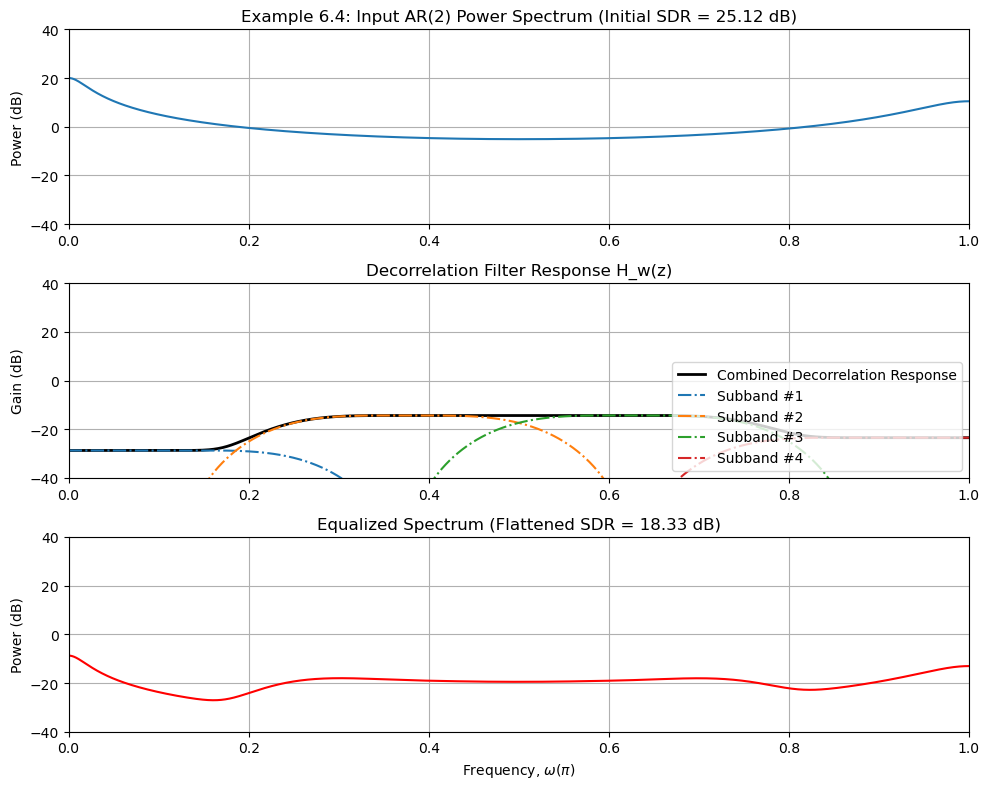

--- Example 6.4 Results ---
Input Spectral Dynamic Range (SDR)     : 25.1190 dB
Equalized Spectral Dynamic Range (SDR) : 18.3280 dB


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import remez, lfilter

# ==========================================
# 1. Helper Functions
# ==========================================
def opt_filter(filtorder: int, N: int):
    """Optimal prototype lowpass FIR filter design."""
    stopedge = 1.0 / N
    passedge = 1.0 / (4 * N)
    tol = 1e-6
    step = 0.1 * passedge
    way = -1
    pcost = 10.0
    flag = False

    while not flag:
        p = remez(filtorder + 1, [0, passedge, stopedge, 1.0], [1, 0], weight=[5, 1], fs=2.0)
        P = np.fft.fft(p, 4096)
        OptRange = int(np.floor(2048 / N))
        phi = np.zeros(OptRange)
        for k in range(1, OptRange + 1):
            phi[k - 1] = np.abs(P[OptRange - k + 1])**2 + np.abs(P[k - 1])**2
        tcost = np.max(np.abs(phi - 1.0))
        if tcost > pcost:
            step /= 2.0
            way = -way
        if np.abs(pcost - tcost) < tol:
            flag = True
        pcost = tcost
        passedge += way * step
    return p, passedge

def make_bank(p: np.ndarray, N: int):
    """Cosine-modulated analysis filter bank."""
    L = len(p)
    H = np.zeros((N, L))
    n = np.arange(L)
    for i in range(N):
        H[i, :] = 2 * p * np.cos((np.pi / N) * (i + 0.5) * (n - (L - 1) / 2.0) + ((-1)**i) * (np.pi / 4.0))
    return H

# ==========================================
# 2. Parameters & Signal Generation (6P4)
# ==========================================
M_taps = 1024                         # Adaptive filter length
N_sub = 4                             # Number of subbands (N = 4)
L_sub = 8 * N_sub                     # Filter bank length (L = 32)

# Generate AR(2) colored process excitation
np.random.seed(42)
wn = np.random.randn(80000)
a = np.array([1.0, -0.1, -0.8])
un = lfilter([1.0], a, wn)
un /= np.std(un)                      # Normalize to unit variance

# ==========================================
# 3. Filter Bank & Frequency Response Computation
# ==========================================
hopt, _ = opt_filter(L_sub - 1, N_sub)
H_bank = np.sqrt(N_sub) * make_bank(hopt, N_sub)

DFTpoint = 4096
w_freq = np.linspace(0, np.pi, DFTpoint // 2 + 1)

# Input signal power spectrum S_uu(e^{j\omega})
A_resp = np.fft.fft(a, DFTpoint)[:DFTpoint // 2 + 1]
HzSig = 1.0 / (np.abs(A_resp)**2)
HzSig /= np.var(un)

# Subband filter magnitude responses |H_i(e^{j\omega})|^2
Hz_mag = np.zeros((N_sub, DFTpoint // 2 + 1))
for i in range(N_sub):
    H_fft = np.fft.fft(H_bank[i, :], DFTpoint)[:DFTpoint // 2 + 1]
    Hz_mag[i, :] = np.abs(H_fft)**2

# Compute equivalent decorrelation filter responses
weight = np.zeros(N_sub)
Hw = np.zeros((N_sub, DFTpoint // 2 + 1))

for i in range(N_sub):
    un_i = lfilter(H_bank[i, :], [1.0], un)
    weight[i] = np.var(un_i) * M_taps
    Hw[i, :] = Hz_mag[i, :] / weight[i]

HwSum = np.sum(Hw, axis=0)
HzSigNor = HzSig * HwSum

# Compute Spectral Dynamic Range (SDR)
SDR_in = 10 * np.log10(np.max(HzSig)) - 10 * np.log10(np.min(HzSig))
SDR_out = 10 * np.log10(np.max(HzSigNor)) - 10 * np.log10(np.min(HzSigNor))

# ==========================================
# 4. Plotting Results
# ==========================================
plt.figure(figsize=(10, 8))

# Subplot 1: Input AR(2) Spectrum
plt.subplot(3, 1, 1)
plt.plot(w_freq / np.pi, 10 * np.log10(HzSig + 1e-12))
plt.title(f'Example 6.4: Input AR(2) Power Spectrum (Initial SDR = {SDR_in:.2f} dB)')
plt.ylabel('Power (dB)'); plt.xlim([0, 1]); plt.ylim([-40, 40]); plt.grid(True)

# Subplot 2: Decorrelation Filter Responses
plt.subplot(3, 1, 2)
plt.plot(w_freq / np.pi, 10 * np.log10(HwSum + 1e-12), 'k', linewidth=2.0, label='Combined Decorrelation Response')
for i in range(N_sub):
    plt.plot(w_freq / np.pi, 10 * np.log10(Hw[i, :] + 1e-12), '-.', label=f'Subband #{i+1}')
plt.title('Decorrelation Filter Response H_w(z)')
plt.ylabel('Gain (dB)'); plt.xlim([0, 1]); plt.ylim([-40, 40]); plt.grid(True); plt.legend(loc='lower right')

# Subplot 3: Equalized / Flattened Spectrum
plt.subplot(3, 1, 3)
plt.plot(w_freq / np.pi, 10 * np.log10(HzSigNor + 1e-12), 'r')
plt.title(f'Equalized Spectrum (Flattened SDR = {SDR_out:.2f} dB)')
plt.xlabel(r'Frequency, $\omega (\pi)$'); plt.ylabel('Power (dB)'); plt.xlim([0, 1]); plt.ylim([-40, 40]); plt.grid(True)

plt.tight_layout()
plt.show()

print(f"--- Example 6.4 Results ---")
print(f"Input Spectral Dynamic Range (SDR)     : {SDR_in:.4f} dB")
print(f"Equalized Spectral Dynamic Range (SDR) : {SDR_out:.4f} dB")

In [9]:
import numpy as np

# ==========================================
# Cell 3: MSAF Core Engine (Fixed Buffer Reshaping)
# ==========================================
class MSAF:
    def __init__(self, w0: np.ndarray, mu: float, N: int, L: int, H: np.ndarray = None, F: np.ndarray = None):
        self.w0 = w0.flatten()
        self.M = len(self.w0)
        self.mu = mu
        self.N = N
        self.L = L
        
        if H is None or F is None:
            p0, _ = opt_filter(L - 1, N)
            H_bank = make_bank(p0, N)
            F_bank = np.fliplr(H_bank)
            self.H = np.sqrt(N) * H_bank.T       # (L, N) matrix
            self.F = np.sqrt(N) * F_bank.T       # (L, N) matrix
        else:
            self.H = H
            self.F = F
            
        self.coeffs = self.w0.copy()
        self.alpha = np.ones(N) * 1e-4
        self.AdaptStart = L + self.M
        self.iter = 0

    def adapt(self, un: np.ndarray, dn: np.ndarray, unknownsys: np.ndarray = None):
        ITER = len(un)
        en = np.zeros(ITER)
        w = self.coeffs.copy()
        
        U = np.zeros((self.M, self.N))
        a_buf = np.zeros(self.L)
        d_buf = np.zeros(self.L)
        A_buf = np.zeros((self.L, self.N))
        z_buf = np.zeros(self.L)
        
        compute_eml = unknownsys is not None
        eml = np.zeros(ITER) if compute_eml else None
        if compute_eml:
            norm_b = np.linalg.norm(unknownsys)
            
        for n in range(ITER):
            d_buf = np.concatenate(([dn[n]], d_buf[:-1]))
            a_buf = np.concatenate(([un[n]], a_buf[:-1]))
            A_buf = np.hstack((a_buf.reshape(-1, 1), A_buf[:, :-1]))
            
            if compute_eml:
                eml[n] = np.linalg.norm(unknownsys - w) / norm_b
                
            if (n + 1) % self.N == 0:
                U1 = (self.H.T @ A_buf).T               # (N, L) -> (N, N) block
                U2 = U[:-self.N, :] if self.M > self.N else np.zeros((0, self.N))
                U = np.vstack((U1, U2))                # Stack along row axis to form (M, N) matrix
                
                dD = self.H.T @ d_buf                  # Partitioned desired vector (N,)
                eD = dD - U.T @ w                      # Error estimation vector (N,)
                
                if (n + 1) >= self.AdaptStart:
                    denom = np.sum(U * U, axis=0) + self.alpha
                    w += U @ (eD / denom) * self.mu
                    self.iter += 1
                    
                z_buf = self.F @ eD + z_buf
                en[n - self.N + 1 : n + 1] = z_buf[:self.N]
                z_buf = np.concatenate((z_buf[self.N:], np.zeros(self.N)))
                
        self.coeffs = w
        return en, eml

In [7]:
from scipy.signal import lfilter

# ==========================================
# Cell 4: Signal Generator
# ==========================================
def generate_responses(iter_samples: int, b: np.ndarray, seed: int = 42, ARtype: int = 1, SNR: float = 40.0):
    np.random.seed(seed)
    un_raw = np.random.randn(iter_samples)
    
    AR_dict = {
        1: [1.0],
        2: [1.0, -0.1, -0.8],
        3: [1.0, -1.6, 0.81],
        4: [5.3217, -9.2948, 7.0933, -2.8152, 2.5805, -2.4230, 0.3747, 2.2628, -0.3028, -1.7444, 1.1053]
    }
    a_coeff = AR_dict.get(ARtype, [1.0])
    
    un = lfilter([1.0], a_coeff, un_raw)
    dn = lfilter(b, [1.0], un)
    
    dn = dn[len(b):]
    un = un[len(b):]
    
    std_d = np.std(dn)
    un /= std_d
    dn /= std_d
    
    if SNR < 100:
        noise_var = 10.0 ** (-SNR / 10.0)
        vn = (np.random.rand(len(dn)) - 0.5) * np.sqrt(12.0 * noise_var)
        dn += vn
    else:
        vn = np.zeros(len(dn))
        
    return un, dn, vn

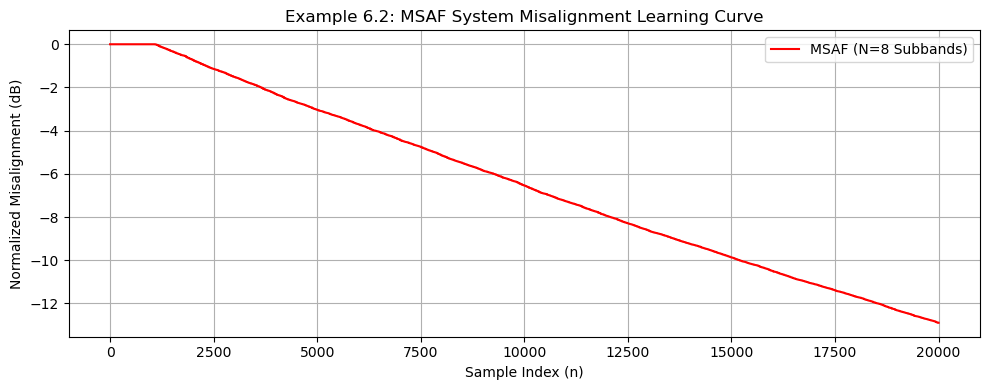

Final MSAF Misalignment: -12.90 dB


In [10]:
import matplotlib.pyplot as plt

# ==========================================
# Cell 5: Example 6.2 Execution
# ==========================================
M_taps = 1024
N_sub = 8
L_sub = 8 * N_sub
mu_step = 0.1
n_iterations = 20000

# Unknown system (b) setup
np.random.seed(0)
b_system = np.random.randn(M_taps)
b_system /= np.linalg.norm(b_system)

# Generate AR(2) excitation signal
un_sig, dn_sig, _ = generate_responses(n_iterations + M_taps, b_system, seed=100, ARtype=2, SNR=40.0)

# Instantiate and run MSAF
msaf_engine = MSAF(w0=np.zeros(M_taps), mu=mu_step, N=N_sub, L=L_sub)
en_out, eml_out = msaf_engine.adapt(un_sig, dn_sig, unknownsys=b_system)

# Plotting Misalignment Learning Curve
plt.figure(figsize=(10, 4))
plt.plot(20 * np.log10(eml_out + 1e-12), 'r', label=f'MSAF (N={N_sub} Subbands)')
plt.title('Example 6.2: MSAF System Misalignment Learning Curve')
plt.xlabel('Sample Index (n)'); plt.ylabel('Normalized Misalignment (dB)')
plt.grid(True); plt.legend(); plt.tight_layout()
plt.show()

print(f"Final MSAF Misalignment: {20 * np.log10(eml_out[-1]):.2f} dB")

In [ ]:
# ==========================================
# NLMS Python Engine (NLMSinit & NLMSadapt)
# ==========================================
class NLMS:
    def __init__(self, w0: np.ndarray, mu: float, leak: float = 0.0):
        self.coeffs = w0.flatten()
        self.M = len(self.coeffs)
        self.mu = mu
        self.leak = leak
        self.alpha = 1e-4
        self.AdaptStart = self.M
        self.iter = 0

    def adapt(self, un: np.ndarray, dn: np.ndarray, unknownsys: np.ndarray = None):
        ITER = len(un)
        yn = np.zeros(ITER)
        en = np.zeros(ITER)
        w = self.coeffs.copy()
        u = np.zeros(self.M)
        
        compute_eml = unknownsys is not None
        eml = np.zeros(ITER) if compute_eml else None
        if compute_eml:
            norm_b = np.linalg.norm(unknownsys)
            
        for n in range(ITER):
            u = np.concatenate(([un[n]], u[:-1]))
            yn[n] = np.dot(w, u)
            en[n] = dn[n] - yn[n]
            
            if compute_eml:
                eml[n] = np.linalg.norm(unknownsys - w) / norm_b
                
            if n >= self.AdaptStart:
                denom = np.dot(u, u) + self.alpha
                w = (1 - self.mu * self.leak) * w + (self.mu * en[n] / denom) * u
                self.iter += 1
                
        self.coeffs = w
        return en, eml